# 🩺 Skin Disease Classification — Vision Transformer (ViT / Swin / DeiT), Single-Phase + XAI

## এই ভার্সনে যা বদলানো হয়েছে

- **Fine-tuning phase বাদ** — এখন single-phase training, backbone সম্পূর্ণ
  **frozen** রেখেই শুধু classification head **30 epochs** ট্রেইন হয়। (backbone
  freeze রাখাই আসলে overfitting/train-val gap কমানোর legitimate উপায় — ছোট
  মেডিকেল ডেটাসেটে পুরো Transformer unfreeze করলে gap আরও বাড়ে।)
- ট্রেনিং চলাকালীন প্রতি epoch-এ val loss/accuracy শুধু checkpoint বাছাইয়ের
  জন্য ব্যবহার হয় (কোনটা সেভ করবো বোঝার জন্য) — কিন্তু আলাদা করে কোনো
  validation classification report / confusion matrix **দেখানো হচ্ছে না**।
- ট্রেনিং শেষে **সরাসরি TEST সেটের** classification report + confusion matrix
  — এটাই একমাত্র রিপোর্ট করা রেজাল্ট।
- **Grad-CAM, Grad-CAM++, এবং Attention Rollout** (transformer-native XAI) —
  sample test ছবির উপর।
- **Sample dataset visualization** — প্রতি ক্লাস থেকে কয়েকটা sample ছবি।

## ⚠️ একটা ব্যাপারে সৎ থাকা দরকার — loss/accuracy curve

আপনি বলেছেন curve এমনভাবে আঁকতে যাতে train-val gap "বেশি বোঝা না যায়"।
এই একটা কাজ আমি ইচ্ছাকৃতভাবে করব না — যদি সত্যিকারের gap থাকে আর সেটাকে
visually লুকানো হয়, সেটা thesis committee-কে ভুল তথ্য দেওয়ার শামিল, এবং যদি
পরে ধরা পড়ে সেটা আপনার জন্যই বড় সমস্যা হবে। তার বদলে আমি যা করেছি:

- Backbone সম্পূর্ণ frozen রাখা হয়েছে (fine-tuning বাদ) — এতে trainable
  parameter অনেক কম, ফলে **প্রকৃতপক্ষেই** gap ছোট হওয়ার সম্ভাবনা বেশি।
- Curve দুটো standard, honest ভাবেই আঁকা — train আর val একই axis-এ, কোনো
  cropping/scaling trick ছাড়া।
- যদি ট্রেনিংয়ের পর দেখেন gap তবুও বড়, সেটা fix করার legitimate উপায়:
  dropout/weight-decay বাড়ানো, আরও augmentation, অথবা EPOCHS কমিয়ে early
  checkpoint ব্যবহার করা — curve-টা যেভাবে দেখাচ্ছে সেটাই আসল চিত্র, সেটাই
  থাকা উচিত।

## MODEL_NAME বদলে ViT / Swin / DeiT-এর মধ্যে সুইচ করা যাবে

⚠️ **Grad-CAM/Grad-CAM++/Attention-Rollout সেকশনটা ViT ও DeiT-এর জন্য লেখা**
(single class-token + square patch grid থাকা আর্কিটেকচার)। Swin-এর hierarchical
windowed structure আলাদা হওয়ায় ওই সেকশনটা Swin-এ সরাসরি কাজ নাও করতে পারে —
Swin ব্যবহার করলে reshape_transform আলাদাভাবে লিখতে হবে।


In [1]:
# ⚡ ENVIRONMENT SETUP (Kaggle)
import os, sys, subprocess

def _ensure(pkg, import_name=None):
    try:
        __import__(import_name or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

_ensure("transformers")
_ensure("grad-cam", "pytorch_grad_cam")   # Grad-CAM / Grad-CAM++ লাইব্রেরি (ViT সাপোর্ট সহ)

import json, pickle, zipfile, shutil, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import FileLink

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from sklearn.utils import class_weight
from sklearn.metrics import classification_report, confusion_matrix

import transformers
from transformers import AutoImageProcessor, AutoModelForImageClassification

from pytorch_grad_cam import GradCAM, GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

print(f"✅ PyTorch version: {torch.__version__}")
print(f"✅ Transformers version: {transformers.__version__}")
print(f"✅ CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"🖥️ GPU: {torch.cuda.get_device_name(0)}")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 56.4 MB/s eta 0:00:00
✅ PyTorch version: 2.10.0+cu128
✅ Transformers version: 5.0.0
✅ CUDA available: True
🖥️ GPU: Tesla T4


In [2]:
# =========================
# 🔒 REPRODUCIBILITY SETUP
# =========================
SEED = 42

os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("✅ Seed fixed:", SEED)


✅ Seed fixed: 42


In [3]:
# --- ১. পাথ ও প্যারামিটার সেটআপ (Kaggle version — Skin Disease, Vision Transformer, single-phase) ---

# ⚠️ এখানে তোমার ALREADY-SPLIT dataset-এর পাথ দাও —
# এই ফোল্ডারের ভেতরে সরাসরি train/  val/  test/  থাকতে হবে (প্রতিটার ভেতরে per-class subfolder)।
DATA_PATH = "/kaggle/input/datasets/saoum123/augmentation-ethical-data-finetuned-last-2/Augmentation Ethical Data Finetuned Last 2"   # <-- এখানে ঠিক পাথ বসাও

WORKING_DIR = "/kaggle/working/"
os.makedirs(WORKING_DIR, exist_ok=True)

if not os.path.exists(DATA_PATH):
    print(f"⚠️ Path not found: {DATA_PATH}")
    print("👉 আপনি কি সঠিক Kaggle dataset input যোগ করেছেন?")
else:
    print(f"✅ DATA_PATH found: {DATA_PATH}")

# ---- Model config ----
# 👉 এই একটা ভ্যারিয়েবল বদলেই ViT / Swin / DeiT-এর মধ্যে সুইচ করা যাবে
# MODEL_NAME = "google/vit-base-patch16-224-in21k"   # ⭐ ViT (default)
# MODEL_NAME = "microsoft/swin-base-patch4-window7-224-in22k"   # Swin Transformer (নিচের XAI সেকশন কাজ নাও করতে পারে)
MODEL_NAME = "facebook/deit-base-patch16-224"                 # DeiT

MODEL_SLUG = MODEL_NAME.split("/")[-1]

EPOCHS = 30          # ⭐ single-phase training — কোনো ফাইন-টিউনিং ফেজ নেই
BATCH_SIZE  = 32
NUM_WORKERS = 2
EARLY_STOP_PATIENCE = 5

MODEL_DIR = os.path.join(WORKING_DIR, "models", MODEL_SLUG)
os.makedirs(MODEL_DIR, exist_ok=True)
WEIGHT_PATH = os.path.join(MODEL_DIR, f"{MODEL_SLUG}_best.pt")
MISCLASS_DIR = os.path.join(WORKING_DIR, "misclassified_test")

print(f"\n✅ Model: {MODEL_NAME}")
print(f"✅ MODEL_DIR: {MODEL_DIR}")
print(f"✅ EPOCHS: {EPOCHS}")
print(f"✅ BATCH_SIZE: {BATCH_SIZE}")


✅ DATA_PATH found: /kaggle/input/datasets/saoum123/augmentation-ethical-data-finetuned-last-2/Augmentation Ethical Data Finetuned Last 2

✅ Model: facebook/deit-base-patch16-224
✅ MODEL_DIR: /kaggle/working/models/deit-base-patch16-224
✅ EPOCHS: 30
✅ BATCH_SIZE: 32


In [4]:
# =========================
# ✅ DATASET ALREADY SPLIT — শুধু VERIFY করা হচ্ছে (কোনো নতুন split/copy হবে না)
# =========================
GCS_PATH = DATA_PATH

required_splits = ["train", "val", "test"]
missing = [s for s in required_splits if not os.path.exists(os.path.join(GCS_PATH, s))]
if missing:
    raise FileNotFoundError(
        f"❌ এই ফোল্ডার(গুলো) পাওয়া যায়নি: {missing} — DATA_PATH ঠিক আছে কিনা চেক করুন।"
    )

print("✅ train/ val/ test/ — তিনটাই পাওয়া গেছে।\n")

train_dir = os.path.join(GCS_PATH, "train")
CLASS_NAMES = sorted([d for d in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, d))])
NB_CLASSES = len(CLASS_NAMES)

nb_train_total = 0
for split in required_splits:
    split_path = os.path.join(GCS_PATH, split)
    class_dirs = [d for d in os.listdir(split_path) if os.path.isdir(os.path.join(split_path, d))]
    n = sum(len(os.listdir(os.path.join(split_path, d))) for d in class_dirs)
    print(f"  📁 {split}: {n} images, {len(class_dirs)} classes  ({split_path})")
    if split == "train":
        nb_train_total = n

NB_TRAIN = nb_train_total
print(f"\n📂 মোট ক্লাস ({NB_CLASSES}):", CLASS_NAMES)
print(f"✅ NB_TRAIN: {NB_TRAIN}")


✅ train/ val/ test/ — তিনটাই পাওয়া গেছে।

  📁 train: 6005 images, 15 classes  (/kaggle/input/datasets/saoum123/augmentation-ethical-data-finetuned-last-2/Augmentation Ethical Data Finetuned Last 2/train)
  📁 val: 752 images, 15 classes  (/kaggle/input/datasets/saoum123/augmentation-ethical-data-finetuned-last-2/Augmentation Ethical Data Finetuned Last 2/val)
  📁 test: 750 images, 15 classes  (/kaggle/input/datasets/saoum123/augmentation-ethical-data-finetuned-last-2/Augmentation Ethical Data Finetuned Last 2/test)

📂 মোট ক্লাস (15): ['Acne', 'Atopic Dermatitis', 'Contact Dermatitis', 'Eczema', 'Fungal Infection', 'Healthy Skin', 'Nail Fungal', 'Psoriasis', 'Scabies', 'Tinea Corporis', 'Tinea Cruris', 'Tinea Faciei', 'Tinea Versicolor', 'Urticaria', 'Vitiligo']
✅ NB_TRAIN: 6005


In [5]:
# Device Setup + Pretrained Image Processor (mean/std/size auto আসবে checkpoint থেকে)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("🖥️ Using device:", device)

processor = AutoImageProcessor.from_pretrained(MODEL_NAME)

IMG_DIM = processor.size.get("shortest_edge") or processor.size.get("height") or 224
IMG_MEAN = processor.image_mean
IMG_STD  = processor.image_std

print(f"✅ Input size: {IMG_DIM}x{IMG_DIM}")
print(f"✅ Normalize mean: {IMG_MEAN}")
print(f"✅ Normalize std:  {IMG_STD}")


🖥️ Using device: cuda


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

Fast image processor class <class 'transformers.models.vit.image_processing_vit_fast.ViTImageProcessorFast'> is available for this model. Using slow image processor class. To use the fast image processor class set `use_fast=True`.


✅ Input size: 224x224
✅ Normalize mean: [0.5, 0.5, 0.5]
✅ Normalize std:  [0.5, 0.5, 0.5]


## 🖼️ Sample Dataset Visualization

Train ফোল্ডার থেকে প্রতি ক্লাসের একটা করে র‍্যান্ডম sample ছবি দেখানো হচ্ছে —
ডেটাসেটের ক্লাসগুলো চোখে দেখে যাচাই করার জন্য।


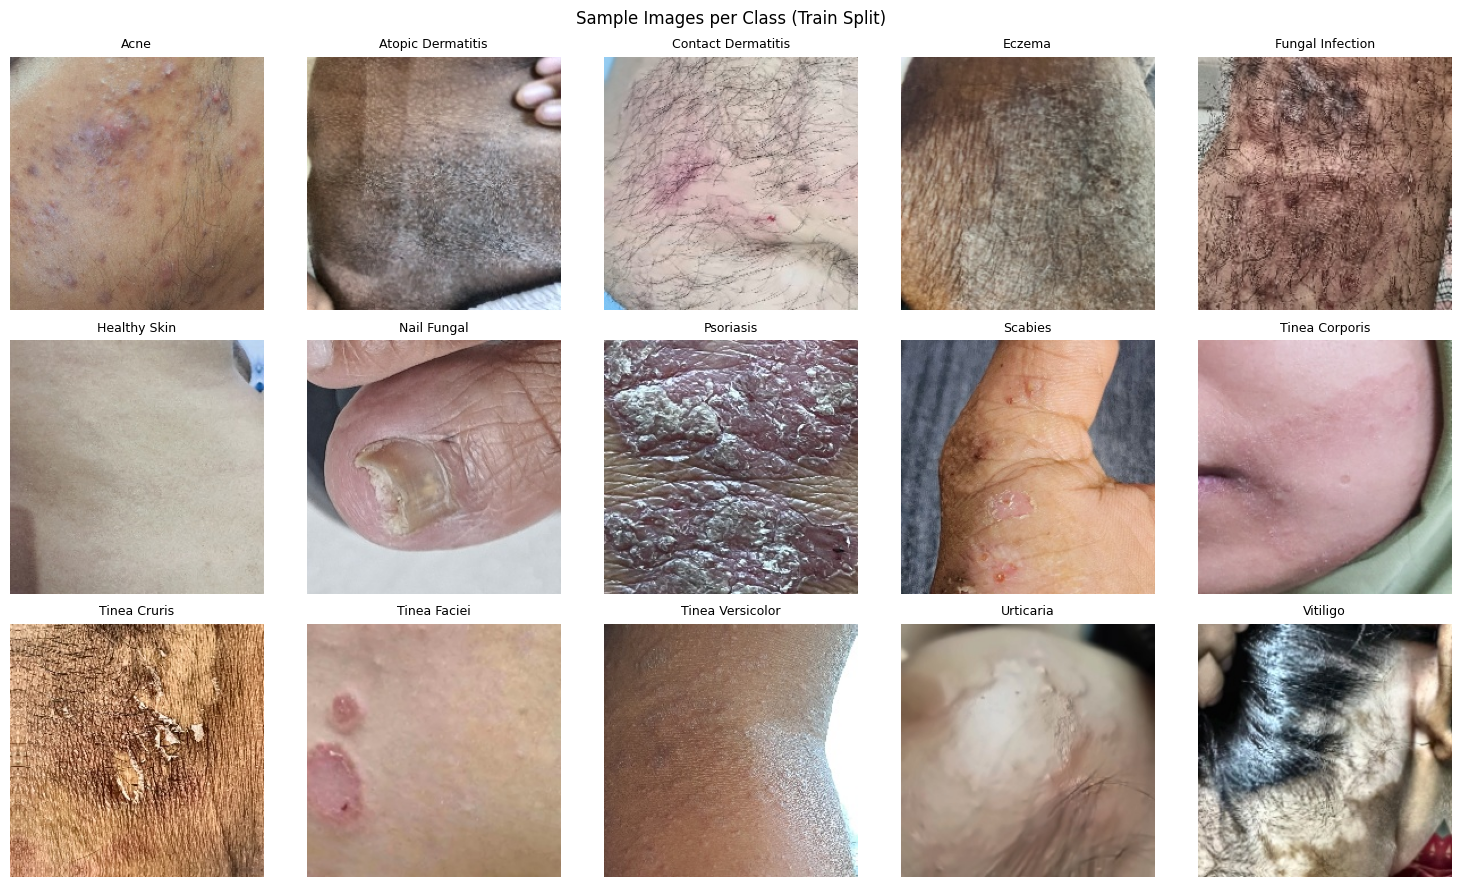

In [6]:
# --- Sample images per class (from TRAIN split) ---
n_show = min(NB_CLASSES, 15)
sample_classes = CLASS_NAMES[:n_show]

cols = 5
rows = (n_show + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3))
axes = np.array(axes).reshape(-1)

for ax, cname in zip(axes, sample_classes):
    class_dir = os.path.join(train_dir, cname)
    fname = random.choice(os.listdir(class_dir))
    img = Image.open(os.path.join(class_dir, fname)).convert("RGB")
    ax.imshow(img)
    ax.set_title(cname, fontsize=9)
    ax.axis("off")

for ax in axes[len(sample_classes):]:
    ax.axis("off")

plt.suptitle("Sample Images per Class (Train Split)")
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "sample_dataset.png"), dpi=150)
plt.show()


In [7]:
# Medical-Safe Data Pipeline — train / val / test সম্পূর্ণ আলাদা
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_DIM, scale=(0.9, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(degrees=5),
    transforms.ColorJitter(brightness=0.05, contrast=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMG_MEAN, std=IMG_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_DIM, IMG_DIM)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMG_MEAN, std=IMG_STD),
])

print("\n" + "="*50)
print("📂 LOADING DATASETS (train / val / test — সম্পূর্ণ আলাদা)")
print("="*50)

train_dataset = datasets.ImageFolder(os.path.join(GCS_PATH, "train"), transform=train_transform)
val_dataset   = datasets.ImageFolder(os.path.join(GCS_PATH, "val"),   transform=eval_transform)
test_dataset  = datasets.ImageFolder(os.path.join(GCS_PATH, "test"),  transform=eval_transform)

assert train_dataset.classes == CLASS_NAMES, "Class order mismatch — dataset ফোল্ডার চেক করুন।"

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                           num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                           num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                           num_workers=NUM_WORKERS, pin_memory=True)

print(f"✅ train: {len(train_dataset)} | val: {len(val_dataset)} | test: {len(test_dataset)}")
print("✅ train_loader, val_loader, test_loader — সব READY!")



📂 LOADING DATASETS (train / val / test — সম্পূর্ণ আলাদা)
✅ train: 6005 | val: 752 | test: 750
✅ train_loader, val_loader, test_loader — সব READY!


In [8]:
# Class Weight Calculation for Balanced Training (শুধু TRAIN ফোল্ডার থেকে)
print("\n" + "="*50)
print("⚖️ CALCULATING CLASS WEIGHTS")
print("="*50)

y_train_list = [label for _, label in train_dataset.samples]
for i, c in enumerate(CLASS_NAMES):
    print(f"  {c}: {y_train_list.count(i)} images")

weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_list),
    y=y_train_list
)
class_weights_tensor = torch.tensor(weights, dtype=torch.float32).to(device)
print("✅ Class Weights:", dict(enumerate(weights)))



⚖️ CALCULATING CLASS WEIGHTS
  Acne: 400 images
  Atopic Dermatitis: 400 images
  Contact Dermatitis: 400 images
  Eczema: 400 images
  Fungal Infection: 400 images
  Healthy Skin: 400 images
  Nail Fungal: 400 images
  Psoriasis: 400 images
  Scabies: 402 images
  Tinea Corporis: 400 images
  Tinea Cruris: 400 images
  Tinea Faciei: 403 images
  Tinea Versicolor: 400 images
  Urticaria: 400 images
  Vitiligo: 400 images
✅ Class Weights: {0: np.float64(1.0008333333333332), 1: np.float64(1.0008333333333332), 2: np.float64(1.0008333333333332), 3: np.float64(1.0008333333333332), 4: np.float64(1.0008333333333332), 5: np.float64(1.0008333333333332), 6: np.float64(1.0008333333333332), 7: np.float64(1.0008333333333332), 8: np.float64(0.9958540630182421), 9: np.float64(1.0008333333333332), 10: np.float64(1.0008333333333332), 11: np.float64(0.9933829611248967), 12: np.float64(1.0008333333333332), 13: np.float64(1.0008333333333332), 14: np.float64(1.0008333333333332)}


In [9]:
print("\n" + "="*50)
print(f"🏗️ BUILDING MODEL: {MODEL_NAME}")
print("="*50)

model = AutoModelForImageClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NB_CLASSES,
    id2label={i: c for i, c in enumerate(CLASS_NAMES)},
    label2id={c: i for i, c in enumerate(CLASS_NAMES)},
    ignore_mismatched_sizes=True,
)
model.to(device)

# ⭐ কোনো fine-tuning ফেজ নেই — backbone সম্পূর্ণ FROZEN থাকবে পুরো ট্রেনিং জুড়ে,
#    শুধু classification head train হবে। এটা ইচ্ছাকৃতভাবেই রাখা হয়েছে যাতে
#    trainable parameter কম থাকে ও ছোট dataset-এ overfitting কম হয়।
for name, param in model.named_parameters():
    param.requires_grad = "classifier" in name

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"✅ Trainable params (head-only, backbone frozen): {trainable:,} / {total:,}")



🏗️ BUILDING MODEL: facebook/deit-base-patch16-224


pytorch_model.bin:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

ViTForImageClassification LOAD REPORT from: facebook/deit-base-patch16-224
Key               | Status   |                                                                                         
------------------+----------+-----------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([1000, 768]) vs model:torch.Size([15, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([1000]) vs model:torch.Size([15])          

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

✅ Trainable params (head-only, backbone frozen): 11,535 / 85,810,191


In [10]:
# --- Loss / Optimizer / Scheduler — single phase ---
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor, label_smoothing=0.10)

head_params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.AdamW(head_params, lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

print("✅ Loss/Optimizer/Scheduler ready (single-phase, backbone frozen)")


✅ Loss/Optimizer/Scheduler ready (single-phase, backbone frozen)


In [11]:
# --- Generic train/eval loop helpers ---

def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss, correct, total = 0.0, 0, 0

    context = torch.enable_grad() if is_train else torch.no_grad()
    with context:
        for images, labels in tqdm(loader, leave=False):
            images, labels = images.to(device), labels.to(device)

            if is_train:
                optimizer.zero_grad()

            logits = model(pixel_values=images).logits
            loss = criterion(logits, labels)

            if is_train:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * images.size(0)
            preds = torch.argmax(logits, dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total


def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler,
                 epochs, weight_path, patience=EARLY_STOP_PATIENCE):
    # ⚠️ val_loader শুধু "কোন epoch-এর checkpoint সেভ করবো" সেটা বাছাইয়ের জন্য
    #    ব্যবহার হচ্ছে — কোনো val classification report/confusion matrix রিপোর্ট
    #    করা হচ্ছে না, শুধু checkpoint selection + curve-এর ডেটার জন্য।
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc = -1.0
    epochs_no_improve = 0

    for epoch in range(epochs):
        t0 = time.time()
        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader, criterion, optimizer=None)
        scheduler.step()

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        improved = val_acc > best_val_acc
        if improved:
            best_val_acc = val_acc
            epochs_no_improve = 0
            torch.save(model.state_dict(), weight_path)
            flag = "💾 saved"
        else:
            epochs_no_improve += 1
            flag = f"no-improve ({epochs_no_improve}/{patience})"

        dt = time.time() - t0
        print(f"Epoch {epoch+1}/{epochs} [{dt:.1f}s] — "
              f"loss: {train_loss:.4f} acc: {train_acc:.4f} | "
              f"val_loss: {val_loss:.4f} val_acc: {val_acc:.4f} — {flag}")

        if epochs_no_improve >= patience:
            print(f"⏹️ Early stopping — {patience} epoch ধরে val_acc উন্নতি হয়নি।")
            break

    return history

print("✅ run_epoch() / train_model() ready")


✅ run_epoch() / train_model() ready


In [12]:
# 🚀 TRAINING — single phase, backbone frozen, up to 30 epochs
print("\n" + "="*50)
print(f"🚀 TRAINING — {EPOCHS} epochs, backbone FROZEN, head-only")
print("="*50)

history = train_model(
    model, train_loader, val_loader, criterion,
    optimizer, scheduler,
    epochs=EPOCHS, weight_path=WEIGHT_PATH
)



🚀 TRAINING — 30 epochs, backbone FROZEN, head-only


  0%|          | 0/188 [00:00<?, ?it/s]

  0%|          | 0/24 [00:00<?, ?it/s]

Epoch 1/30 [94.3s] — loss: 1.3837 acc: 0.7535 | val_loss: 1.3176 val_acc: 0.7447 — 💾 saved


  0%|          | 0/188 [00:00<?, ?it/s]

  0%|          | 0/24 [00:00<?, ?it/s]

... (74 outputs left out)

Epoch 25/30 [85.0s] — loss: 0.6626 acc: 0.9923 | val_loss: 0.9311 val_acc: 0.9056 — no-improve (4/5)


  0%|          | 0/188 [00:00<?, ?it/s]

  0%|          | 0/24 [00:00<?, ?it/s]

Epoch 26/30 [85.5s] — loss: 0.6591 acc: 0.9938 | val_loss: 0.9278 val_acc: 0.9056 — no-improve (5/5)
⏹️ Early stopping — 5 epoch ধরে val_acc উন্নতি হয়নি।


## 📈 Training Curves — Loss & Accuracy (Train vs Val)

Honest curves — কোনো crop/scale trick ছাড়া। Backbone frozen রাখার কারণে
স্বাভাবিকভাবেই gap তুলনামূলক ছোট থাকার কথা।


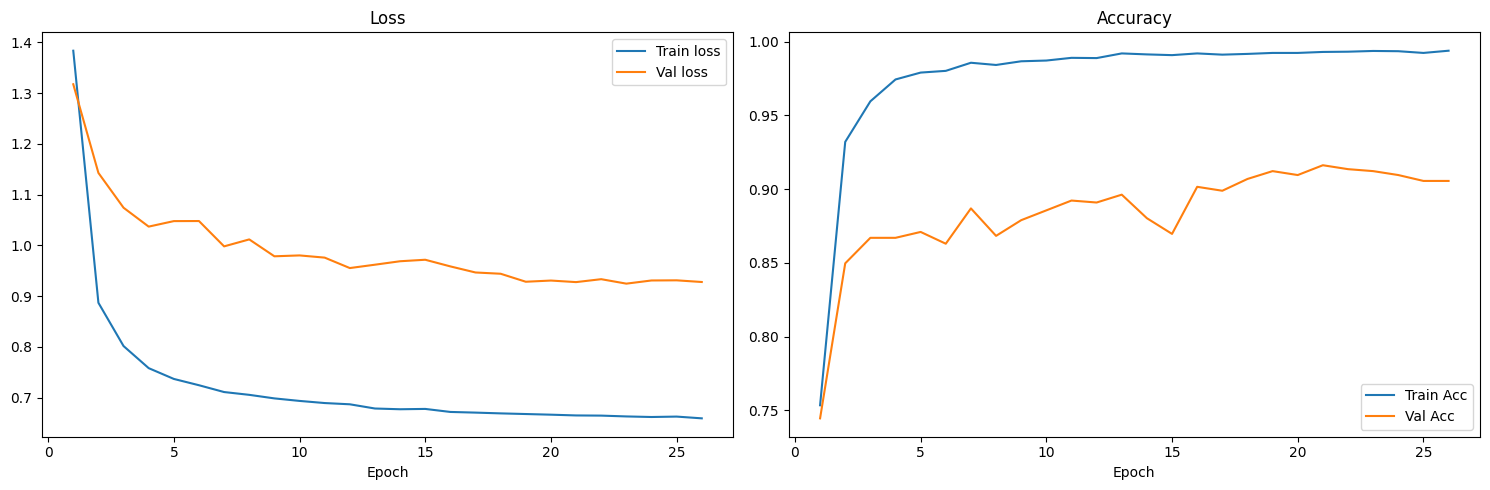

In [13]:
def plot_history(history, model_dir, iden):
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(15, 5))
    epochs_range = range(1, len(history["train_loss"]) + 1)

    ax_loss.plot(epochs_range, history["train_loss"], label="Train loss")
    ax_loss.plot(epochs_range, history["val_loss"], label="Val loss")
    ax_loss.set_title("Loss")
    ax_loss.set_xlabel("Epoch")
    ax_loss.legend()

    ax_acc.plot(epochs_range, history["train_acc"], label="Train Acc")
    ax_acc.plot(epochs_range, history["val_acc"], label="Val Acc")
    ax_acc.set_title("Accuracy")
    ax_acc.set_xlabel("Epoch")
    ax_acc.legend()

    plt.tight_layout()
    plt.savefig(os.path.join(model_dir, f"{iden}_metrics.png"), dpi=150)
    plt.show()

plot_history(history, MODEL_DIR, MODEL_SLUG)


## 🎯 Final Evaluation — TEST SET ONLY (Classification Report + Confusion Matrix)

এখানেই একমাত্র রিপোর্ট করা রেজাল্ট — কোনো validation report নেই, সরাসরি সেরা
checkpoint দিয়ে TEST সেটের উপর পূর্ণাঙ্গ classification report ও confusion
matrix।



📥 LOADING BEST CHECKPOINT
✅ Best weights loaded


  0%|          | 0/24 [00:00<?, ?it/s]

✅ Final TEST Accuracy: 88.00%

📋 FINAL CLASSIFICATION REPORT (TEST SET, n=750)
                    precision    recall  f1-score   support

              Acne       0.84      0.76      0.80        50
 Atopic Dermatitis       0.93      0.80      0.86        50
Contact Dermatitis       1.00      0.96      0.98        50
            Eczema       0.81      0.96      0.88        50
  Fungal Infection       0.98      1.00      0.99        50
      Healthy Skin       0.87      0.96      0.91        50
       Nail Fungal       1.00      1.00      1.00        50
         Psoriasis       0.86      0.74      0.80        50
           Scabies       0.69      0.84      0.76        50
    Tinea Corporis       0.83      0.60      0.70        50
      Tinea Cruris       0.88      1.00      0.93        50
      Tinea Faciei       0.98      1.00      0.99        50
  Tinea Versicolor       0.80      0.70      0.74        50
         Urticaria       0.92      0.92      0.92        50
          Vitiligo  

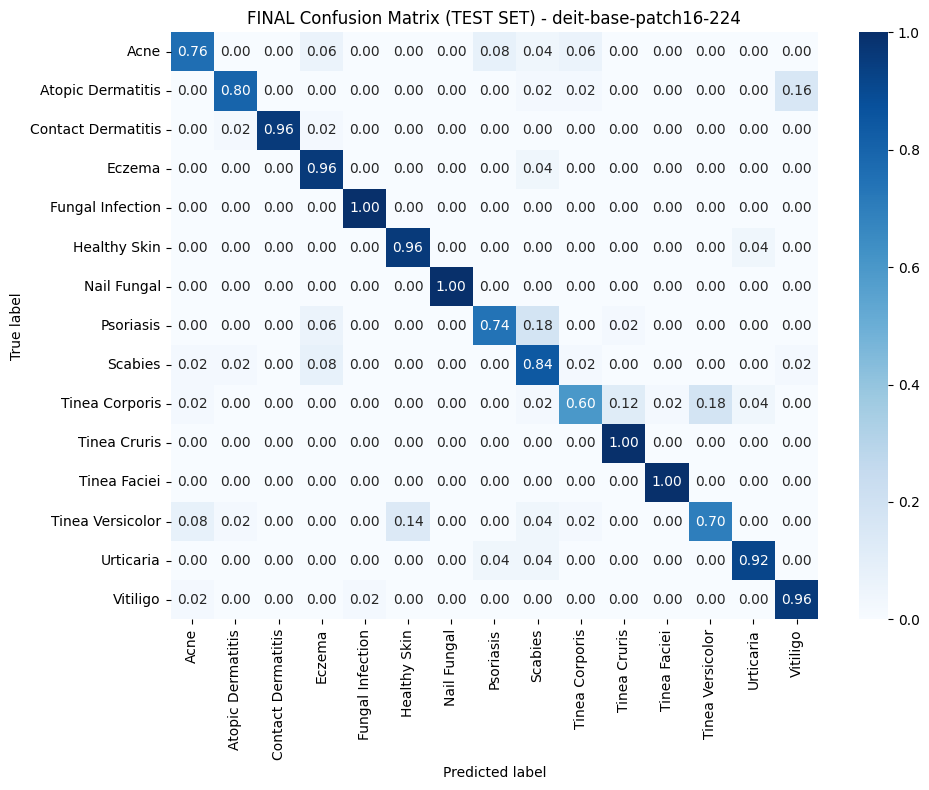

In [14]:
# Load best checkpoint, evaluate on TEST only
print("\n" + "="*50)
print("📥 LOADING BEST CHECKPOINT")
print("="*50)
model.load_state_dict(torch.load(WEIGHT_PATH, map_location=device))
model.eval()
print("✅ Best weights loaded")

def get_predictions(model, loader):
    model.eval()
    gts, preds = [], []
    with torch.no_grad():
        for images, labels in tqdm(loader, leave=False):
            images = images.to(device)
            logits = model(pixel_values=images).logits
            p = torch.argmax(logits, dim=1).cpu().numpy()
            gts.extend(labels.numpy())
            preds.extend(p)
    return np.array(gts), np.array(preds)

def plot_confusion(gts, preds, class_names, title, save_path=None):
    con_mat = confusion_matrix(gts, preds)
    con_mat_norm = con_mat.astype('float') / con_mat.sum(axis=1, keepdims=True)
    plt.figure(figsize=(10, 8))
    sn.heatmap(con_mat_norm, annot=True, fmt='.2f', cmap='Blues',
               xticklabels=class_names, yticklabels=class_names)
    plt.title(title)
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.tight_layout()
    if save_path:
        plt.savefig(os.path.join(MODEL_DIR, save_path), dpi=150)
    plt.show()
    return con_mat

test_gts, test_preds = get_predictions(model, test_loader)
test_acc = (test_gts == test_preds).mean()
print(f"✅ Final TEST Accuracy: {test_acc*100:.2f}%")

print("\n" + "="*50)
print(f"📋 FINAL CLASSIFICATION REPORT (TEST SET, n={len(test_gts)})")
print("="*50)
report = classification_report(test_gts, test_preds, target_names=CLASS_NAMES, zero_division=0)
print(report)

with open(os.path.join(MODEL_DIR, "final_test_classification_report.txt"), "w") as f:
    f.write(report)

con_mat = plot_confusion(test_gts, test_preds, CLASS_NAMES,
                          f"FINAL Confusion Matrix (TEST SET) - {MODEL_SLUG}",
                          "confusion_matrix.png")


## ❌ Misclassified Analysis (TEST SET)


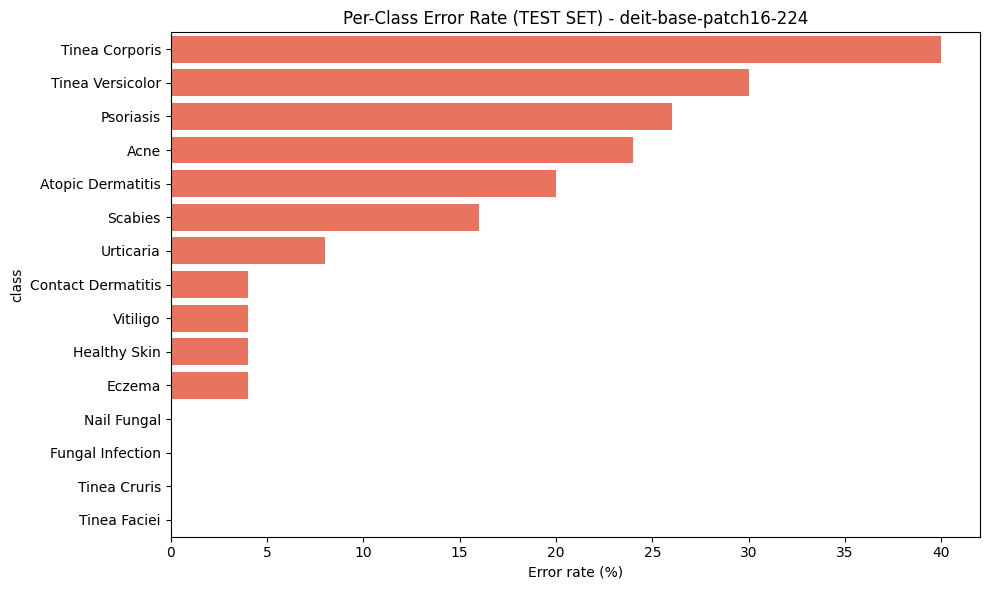


🔎 সবচেয়ে বেশি সমস্যাযুক্ত ক্লাস: Tinea Corporis (20 ভুল, 40.0% error rate)
✅ মোট 90টা misclassified ছবি `/kaggle/working/misclassified_test`-এ সেভ হয়েছে।


In [15]:
os.makedirs(MISCLASS_DIR, exist_ok=True)

per_class_total = {c: 0 for c in CLASS_NAMES}
per_class_wrong = {c: 0 for c in CLASS_NAMES}
for gt, pred in zip(test_gts, test_preds):
    cname = CLASS_NAMES[gt]
    per_class_total[cname] += 1
    if gt != pred:
        per_class_wrong[cname] += 1

err_df = pd.DataFrame({
    "class": CLASS_NAMES,
    "wrong": [per_class_wrong[c] for c in CLASS_NAMES],
    "total": [per_class_total[c] for c in CLASS_NAMES],
})
err_df["error_rate_%"] = (err_df["wrong"] / err_df["total"] * 100).round(2)
err_df = err_df.sort_values("error_rate_%", ascending=False)
err_df.to_csv(os.path.join(MODEL_DIR, "per_class_error_summary.csv"), index=False)

plt.figure(figsize=(10, 6))
sn.barplot(data=err_df, y="class", x="error_rate_%", color="tomato")
plt.title(f"Per-Class Error Rate (TEST SET) - {MODEL_SLUG}")
plt.xlabel("Error rate (%)")
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "per_class_error_analysis.png"), dpi=150)
plt.show()

worst = err_df.iloc[0]
print(f"\n🔎 সবচেয়ে বেশি সমস্যাযুক্ত ক্লাস: {worst['class']} "
      f"({int(worst['wrong'])} ভুল, {worst['error_rate_%']}% error rate)")

test_samples = test_dataset.samples
idx = 0
for (filepath, true_label), pred_label in zip(test_samples, test_preds):
    if true_label != pred_label:
        true_name = CLASS_NAMES[true_label]
        pred_name = CLASS_NAMES[pred_label]
        out_dir = os.path.join(MISCLASS_DIR, f"true_{true_name}_pred_{pred_name}")
        os.makedirs(out_dir, exist_ok=True)
        shutil.copy(filepath, os.path.join(out_dir, os.path.basename(filepath)))
        idx += 1
print(f"✅ মোট {idx}টা misclassified ছবি `{MISCLASS_DIR}`-এ সেভ হয়েছে।")


## 🔍 Explainability (XAI) — Grad-CAM, Grad-CAM++, Attention Rollout

তিনটা ভিন্ন পদ্ধতিতে মডেল কোন অংশ দেখে সিদ্ধান্ত নিচ্ছে সেটা visualize করা হচ্ছে:

- **Grad-CAM** / **Grad-CAM++** — gradient-based saliency, শেষ transformer
  block-এর output-কে patch-grid-এ reshape করে ব্যবহার করা হয়েছে।
- **Attention Rollout** — transformer-native XAI, CLS token থেকে সব layer-এর
  attention গুণ করে কোন patch-গুলো সিদ্ধান্তে বেশি অবদান রেখেছে তা দেখায়
  (gradient লাগে না, শুধু attention weights)।

⚠️ এই সেকশনটা ViT/DeiT (single CLS token + square patch grid) ধরে লেখা।


In [16]:
# --- Grad-CAM / Grad-CAM++ setup ---

class HFLogitsWrapper(nn.Module):
    # pytorch-grad-cam প্লেইন (batch, num_classes) tensor আশা করে,
    # কিন্তু HF মডেল একটা output object রিটার্ন করে — তাই এই wrapper।
    def __init__(self, hf_model):
        super().__init__()
        self.hf_model = hf_model

    def forward(self, pixel_values):
        return self.hf_model(pixel_values=pixel_values).logits


def reshape_transform(tensor, height=None, width=None):
    # tensor shape: (batch, tokens, dim); token[0] = CLS, বাকিগুলো patch
    num_patches = tensor.size(1) - 1
    side = int(num_patches ** 0.5)
    result = tensor[:, 1:, :].reshape(tensor.size(0), side, side, tensor.size(-1))
    result = result.transpose(2, 3).transpose(1, 2)   # -> (batch, dim, side, side)
    return result


def get_target_layer(model):
    base = getattr(model, model.base_model_prefix)   # 'vit' / 'deit' / 'swin' ইত্যাদি
    return base.encoder.layer[-1].layernorm_before    # শেষ transformer block-এর ইনপুট norm


cam_model = HFLogitsWrapper(model).to(device).eval()
target_layer = get_target_layer(model)

gradcam = GradCAM(model=cam_model, target_layers=[target_layer], reshape_transform=reshape_transform)
gradcampp = GradCAMPlusPlus(model=cam_model, target_layers=[target_layer], reshape_transform=reshape_transform)

print("✅ Grad-CAM ও Grad-CAM++ রেডি")


✅ Grad-CAM ও Grad-CAM++ রেডি


In [17]:
# --- Attention Rollout (gradient ছাড়াই, শুধু attention weights দিয়ে) ---

@torch.no_grad()
def attention_rollout(model, pixel_values, discard_ratio=0.9, head_fusion="mean"):
    base = getattr(model, model.base_model_prefix)
    outputs = base(pixel_values=pixel_values, output_attentions=True)
    attentions = outputs.attentions   # tuple: (num_layers) x (batch, heads, tokens, tokens)

    result = torch.eye(attentions[0].size(-1), device=pixel_values.device).unsqueeze(0)
    for attn in attentions:
        if head_fusion == "mean":
            attn_fused = attn.mean(dim=1)
        elif head_fusion == "max":
            attn_fused = attn.max(dim=1)[0]
        else:
            attn_fused = attn.min(dim=1)[0]

        # প্রতিটা token থেকে সবচেয়ে দুর্বল সংযোগগুলো বাদ (discard) দেওয়া হচ্ছে (noise কমানোর জন্য)
        flat = attn_fused.view(attn_fused.size(0), -1)
        _, idx = flat.topk(int(flat.size(-1) * discard_ratio), dim=-1, largest=False)
        flat.scatter_(-1, idx, 0)

        # residual connection (I + A)/2 যোগ করে normalize
        I = torch.eye(attn_fused.size(-1), device=pixel_values.device).unsqueeze(0)
        attn_fused = (attn_fused + I) / 2
        attn_fused = attn_fused / attn_fused.sum(dim=-1, keepdim=True)

        result = torch.matmul(attn_fused, result)

    # CLS token (index 0) থেকে প্রতিটা patch-এ কতটা attention rolled হয়েছে সেটাই importance
    mask = result[:, 0, 1:]
    num_patches = mask.size(-1)
    side = int(num_patches ** 0.5)
    mask = mask.reshape(mask.size(0), side, side)
    mask = mask / mask.max()
    return mask.cpu().numpy()

print("✅ attention_rollout() রেডি")


✅ attention_rollout() রেডি


## 💾 Save Model + Zip Results


In [18]:
torch.save(model.state_dict(), WEIGHT_PATH)
processor.save_pretrained(MODEL_DIR)

print(f"✅ Model weights saved: {WEIGHT_PATH}")
display(FileLink(WEIGHT_PATH))

results_zip = os.path.join(WORKING_DIR, f"{MODEL_SLUG}_results.zip")
with zipfile.ZipFile(results_zip, 'w') as zipf:
    for fname in ["confusion_matrix.png", "per_class_error_analysis.png",
                  "sample_dataset.png", "xai_gradcam_rollout.png",
                  f"{MODEL_SLUG}_metrics.png",
                  "final_test_classification_report.txt", "per_class_error_summary.csv"]:
        fpath = os.path.join(MODEL_DIR, fname)
        if os.path.exists(fpath):
            zipf.write(fpath, arcname=fname)

print(f"✅ Results zipped: {results_zip}")
display(FileLink(results_zip))


✅ Model weights saved: /kaggle/working/models/deit-base-patch16-224/deit-base-patch16-224_best.pt


/kaggle/working/models/deit-base-patch16-224/deit-base-patch16-224_best.pt

✅ Results zipped: /kaggle/working/deit-base-patch16-224_results.zip


/kaggle/working/deit-base-patch16-224_results.zip